# Datasets and Data Splitting with Scikit-learn

<!--<badge>--><a href="https://colab.research.google.com/github/kuennethgroup/ml_in_ms_wt26/blob/main/03_ex/datasets_and_splitting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a><!--</badge>-->

## Understanding `make_blobs` in Scikit-learn

In machine learning, especially when developing and testing clustering algorithms, it's useful to work with synthetic datasets where we already know the ground truth. Scikit-learn's `datasets` module provides a handy function called `make_blobs` for this very purpose. This function allows us to generate datasets with "blobs", i.e., groups of points clustered together, where each blob typically represents a distinct class or category.


Specifically, `make_blobs` generates isotropic Gaussian blobs:

- Gaussian: The points within each blob are distributed according to a Gaussian (or normal) distribution. This means points are more likely to be near the center of the blob.
- Isotropic: "Isotropic" means that the standard deviation of the points is the same in all feature dimensions. In simpler terms, the blobs are roughly spherical. If they were anisotropic, they might be elongated or squished in certain directions.

**Exercise** 

- Understand the code line by line -> use [perplexity.ai](https://www.perplexity.ai/) for help  
<img src="../assets/data.png" alt="drawing" width="400"/>

- Change `n_samples_val` to a smaller number (e.g., 50) and then a larger one (e.g., 500). How does the density of points change?

- Modify `centers_val` to an integer (e.g., 2, then 5). See how the number of blobs changes and where they are positioned randomly.
- Decrease `cluster_std_val` (e.g., to 0.3). How does this affect the "tightness" of the blobs?
- Run the script multiple times with `random_state_val` set to a specific integer (e.g., 10). The plot should be identical each time.

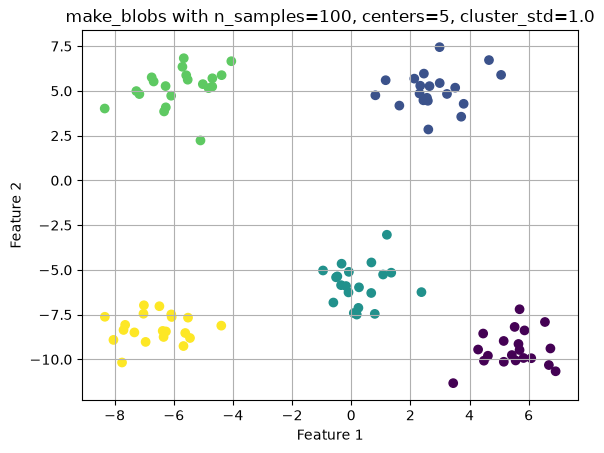

In [1]:
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt
import pandas as pd

# Initial parameters
n_samples_val = 100
centers_val = 5
cluster_std_val = 1.0
n_features_val = 2
random_state_val = 10


data = make_blobs(
    n_samples=n_samples_val,
    centers=centers_val,
    cluster_std=cluster_std_val,
    n_features=n_features_val,
    random_state=random_state_val,
)

column_names = [f"feat{n}" for n in range(data[0].shape[1])]
df_blob = pd.DataFrame(data[0], columns=column_names)
df_blob["target"] = data[1]

if n_features_val == 2:
    plt.scatter(x=df_blob["feat0"], y=df_blob["feat1"], c=df_blob["target"])
    plt.title(
        f"make_blobs with n_samples={n_samples_val}, centers={centers_val}, cluster_std={cluster_std_val}"
    )
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.grid(True)
    plt.show()
else:
    print(
        f"Data generated with {n_features_val} features. Add 3D plotting or other analysis for higher dimensions."
    )
    print("Shape of the DataFrame:", df_blob.shape)

### Regression Tasks with `make_regression`

Scikit-learn's `datasets` module provides the `make_regression` function, a tool for generating regression datasets.

This function creates a set of input features (`X`) and a corresponding continuous target variable (`y`). The target variable is generated as a linear combination of the input features, with optional Gaussian noise added to simulate real-world scenarios where relationships are not perfectly deterministic.

**Exercise** 

- Play with the parameters of `make_regression` and see how the plot changes.

True coefficients: 19.447817432203816, bias: 5.0


,feat0,target
0,0.004291,17.326306
1,-0.255280,-2.844926
2,0.433026,13.484577
3,-0.112272,0.788910
4,0.249179,-0.003591


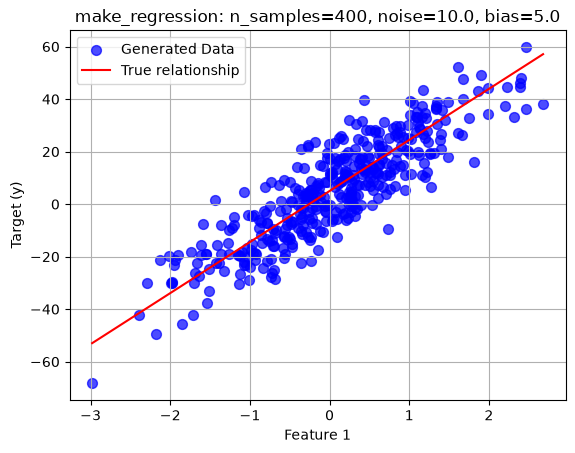

In [2]:
from sklearn.datasets import make_regression
import matplotlib.pyplot as plt
import numpy as np

# Initial parameters
n_samples_val = 400
n_features_val = 1  # Start with 1 feature for easy 2D plotting
noise_val = 10.0
bias_val = 5.0
random_state_val = 10


X, y, coef = make_regression(
    n_samples=n_samples_val,
    n_features=n_features_val,
    noise=noise_val,
    bias=bias_val,
    coef=True,  # also return the true coefficients
    random_state=random_state_val,
)
print(f"True coefficients: {coef}, bias: {bias_val}")

column_names = [f"feat{n}" for n in range(X.shape[1])]
df_reg = pd.DataFrame(X, columns=column_names)
df_reg["target"] = y
display(df_reg.head())

# Visualize the data (for 1 feature)
if n_features_val == 1:
    plt.scatter(
        df_reg["feat0"],
        df_reg["target"],
        color="blue",
        s=50,
        alpha=0.7,
        label="Generated Data",
    )
    # True relationship: y = bias + coef * x
    x_line = np.linspace(df_reg["feat0"].min(), df_reg["feat0"].max(), 2)
    plt.plot(x_line, bias_val + np.ravel(coef)[0] * x_line, "r-", label="True relationship")

    plt.title(
        f"make_regression: n_samples={n_samples_val}, noise={noise_val}, bias={bias_val}"
    )
    plt.xlabel("Feature 1")
    plt.ylabel("Target (y)")
    plt.legend()
    plt.grid(True)
    plt.show()
else:
    print(
        f"Data generated with {n_features_val} features. No plotting for higher dimensions."
    )

**Exercise** 

- Change `n_samples_val` (e.g., to 20, then to 500). How does the plot change in terms of point density?
- Set `noise_val` to 0.0. What do you observe about the data points relative to the true relationship line?
- Modify `bias_val` (e.g., -10.0, 0.0, 25.0). How does the position of the true relationship line (and the data cloud) shift vertically?
- Run the script multiple times with `random_state_val` set to a fixed integer (e.g., 15). The plot and coefficients should be identical.

### Splitting Data for Model Evaluation with scikit-learn

This explains how to split your dataset for model evaluation using the `train_test_split` function from scikit-learn. We'll also see how to make your splits reproducible and visualize the results.

Read through the [train_test_split](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html#sklearn.model_selection.train_test_split) documentation.

<img src="../assets/error_separate_test.drawio.png" alt="drawing" width="500"/>


**Exercise** 

- Divide your dataset so that 80% is used for training the model and 20% is reserved for testing its performance. 
- Ensure that this data split can be reproduced exactly by setting a random seed (`random_state` in scikit-learn) to 10.
- Visualize the split by creating a scatter plot of a feature (e.g., feat0) against the target variable (target). Use distinct colors to differentiate between the data points belonging to the training set and the test set, all on the same plot.


- Change the split from 80/20 to 70/30.
- Change the random seed to 20 and run the cell multiple times.
- Run the cell multiple times without a random seed.

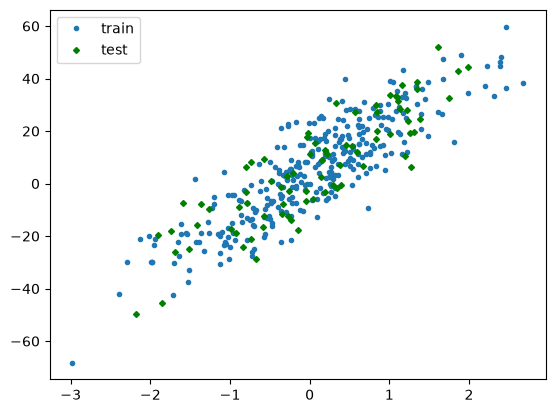

In [3]:
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 1)

# Use the arguments test_size and random_state in the function to create test and train sets.
df_train, df_test = train_test_split(df_reg, test_size=0.2, random_state=10)

ax.plot(df_train["feat0"], df_train["target"], "o", ms=3, label="train")
ax.plot(df_test["feat0"], df_test["target"], "D", ms=3, color="g", label="test")
ax.legend()

### Why do we split?

A flexible model can memorize the training data. It then looks perfect on the training set but fails on new data. The test set reveals this (overfitting).

**Exercise**

- Run the cell. How do the train and test RMSE change with `max_depth`?
- Which `max_depth` would you choose?
- Why should you **not** use the test set to choose `max_depth`?

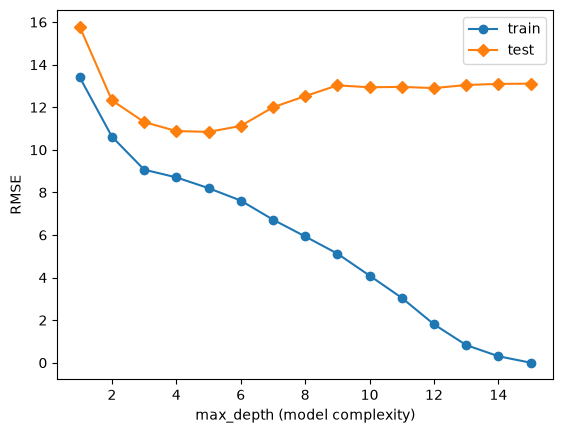

In [4]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import root_mean_squared_error

depths = range(1, 16)
rmse_train, rmse_test = [], []

for depth in depths:
    model = DecisionTreeRegressor(max_depth=depth, random_state=10)
    model.fit(df_train[["feat0"]], df_train["target"])
    rmse_train.append(root_mean_squared_error(df_train["target"], model.predict(df_train[["feat0"]])))
    rmse_test.append(root_mean_squared_error(df_test["target"], model.predict(df_test[["feat0"]])))

plt.plot(depths, rmse_train, "o-", label="train")
plt.plot(depths, rmse_test, "D-", label="test")
plt.xlabel("max_depth (model complexity)")
plt.ylabel("RMSE")
plt.legend()

### k-Fold Cross-Validation with scikit-learn

This guide details how to implement k-fold cross-validation for robust model evaluation using the `KFold` class from scikit-learn. We will also discuss how to visualize the data splits for each fold.

Read through the [KFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.KFold.html) documentation.


<img src="../assets/k-fold.drawio.png" alt="drawing" width="300"/>


**Exercise** 

- Utilize k-fold cross-validation to split your dataset for model evaluation.
- Set `shuffle=False`. Why does shuffling matter if a dataset is sorted (e.g., by material or property)?
- Create a scatter plot of a specific feature (e.g., feat0) against the target variable (target).
- On this plot, use distinct colors to differentiate between the data points belonging to the current fold's training set and its test set.


- Modify the number of folds used in your k-fold cross-validation setup. Experiment with the following values for `n_splits`: 3, 5, 8, 9, and 10.

Consider the following when changing `n_splits`:
- Computational Cost: More folds mean more models to train, increasing the overall computation time.
- Bias-Variance Trade-off:
  - A smaller k (e.g., 3) means larger validation sets and smaller training sets for each fold. This can lead to a more biased estimate of model performance (as models are trained on less data) but with lower variance (as the validation sets are larger).
  - A larger k (e.g., 10, or even Leave-One-Out Cross-Validation where k equals the number of samples) means the training sets are very similar to the entire dataset, leading to a less biased estimate. However, the variance of the performance estimate can be higher, and it's computationally more expensive.
  - Dataset Size: If you have a very small dataset, a larger k might result in validation folds that are too small to be representative.

Split 0: Test points: 80 | Train points: 320
Split 1: Test points: 80 | Train points: 320
Split 2: Test points: 80 | Train points: 320
Split 3: Test points: 80 | Train points: 320
Split 4: Test points: 80 | Train points: 320


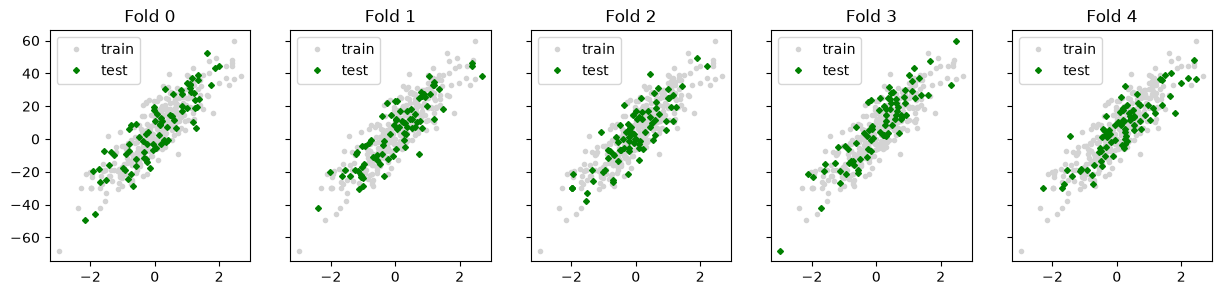

In [5]:
from sklearn.model_selection import KFold

n_splits = 5

fig, axx = plt.subplots(1, n_splits, figsize=(15, 3), sharex=True, sharey=True)

kf = KFold(n_splits=n_splits, shuffle=True, random_state=10)

for num, ((train_index, test_index), ax) in enumerate(zip(kf.split(df_reg), axx)):
    df_train_fold = df_reg.iloc[train_index]
    df_test_fold = df_reg.iloc[test_index]
    ax.plot(df_train_fold["feat0"], df_train_fold["target"], "o", ms=3, color="lightgray", label="train")
    ax.plot(df_test_fold["feat0"], df_test_fold["target"], "D", ms=3, color="g", label="test")
    ax.set_title(f"Fold {num}")
    ax.legend()

    print(f"Split {num}: Test points: {len(df_test_fold)} | Train points: {len(df_train_fold)}")

### Train, validation, and test sets

The test set is used only **once**, at the very end. To choose hyperparameters (e.g., `max_depth`), we use cross-validation on the training set. The held-out folds are called validation sets.

<img src="../assets/k-fold.drawio.png" alt="drawing" width="300"/>

**Exercise**

- Run the cell. Which `max_depth` has the lowest cross-validation RMSE?
- Change `n_splits` to 3 and 10. How do the mean and the standard deviation of the RMSE change?
- Is the final test RMSE close to the cross-validation RMSE?

In [6]:
from sklearn.model_selection import cross_val_score

cv = KFold(n_splits=5, shuffle=True, random_state=10)

cv_rmse = {}
for depth in depths:
    model = DecisionTreeRegressor(max_depth=depth, random_state=10)
    # Cross-validation on the training set only
    scores = -cross_val_score(
        model, df_train[["feat0"]], df_train["target"], cv=cv, scoring="neg_root_mean_squared_error"
    )
    cv_rmse[depth] = scores.mean()
    print(f"max_depth={depth:2}: RMSE = {scores.mean():.2f} ± {scores.std():.2f}")

best_depth = min(cv_rmse, key=cv_rmse.get)

# Final model: train on the whole training set, evaluate once on the test set
model = DecisionTreeRegressor(max_depth=best_depth, random_state=10)
model.fit(df_train[["feat0"]], df_train["target"])
print(f"\nBest max_depth: {best_depth}")
print(f"Test RMSE: {root_mean_squared_error(df_test['target'], model.predict(df_test[['feat0']])):.2f}")

max_depth= 1: RMSE = 14.12 ± 0.80
max_depth= 2: RMSE = 11.94 ± 0.59
max_depth= 3: RMSE = 10.46 ± 0.37
max_depth= 4: RMSE = 10.44 ± 0.61
max_depth= 5: RMSE = 10.86 ± 0.60
max_depth= 6: RMSE = 11.06 ± 0.44
max_depth= 7: RMSE = 11.64 ± 0.87
max_depth= 8: RMSE = 12.35 ± 0.84
max_depth= 9: RMSE = 12.77 ± 0.63
max_depth=10: RMSE = 12.99 ± 0.72
max_depth=11: RMSE = 13.18 ± 0.65
max_depth=12: RMSE = 13.26 ± 0.62
max_depth=13: RMSE = 13.30 ± 0.66
max_depth=14: RMSE = 13.35 ± 0.75
max_depth=15: RMSE = 13.35 ± 0.75

Best max_depth: 4
Test RMSE: 10.88


### Stratified splits

For classification, each fold should contain all classes in the same ratio. This matters if a class is rare.

**Exercise**

- Run the cell. How many samples of the rare class end up in each test fold with `KFold` and with `StratifiedKFold`?
- Change the ratio to 95:5. What happens with `KFold`?

In [7]:
from sklearn.model_selection import StratifiedKFold

# Imbalanced blobs: 90 samples of class 0, 10 samples of class 1
X_imb, y_imb = make_blobs(n_samples=[90, 10], n_features=2, random_state=10)

print(f"{y_imb = }")
for splitter in [
    KFold(n_splits=5, shuffle=True, random_state=1),
    StratifiedKFold(n_splits=5, shuffle=True, random_state=1),
]:
    rare_per_fold = [int(y_imb[test_index].sum()) for _, test_index in splitter.split(X_imb, y_imb)]
    print(f"{type(splitter).__name__:16}: rare samples per test fold = {rare_per_fold}")

y_imb = array([0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0])
KFold           : rare samples per test fold = [0, 3, 1, 4, 2]
StratifiedKFold : rare samples per test fold = [2, 2, 2, 2, 2]
StratifiedKFold : rare samples per test fold = [2, 2, 2, 2, 2]


### Grouped splits

In materials data, the same material is often measured several times. With a random split, near-copies of a material end up in both the training and the test set, and the model looks better than it is. `GroupKFold` keeps all samples of a material in the same fold.

**Exercise**

- Run the cell. Why is the R² of the random split higher?
- Which R² tells you how well the model works for a **new** material?

In [8]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold

rng = np.random.default_rng(10)

# 40 materials, each measured 5 times with small measurement noise
n_materials, n_repeats = 40, 5
descriptors = rng.normal(size=(n_materials, 5))
prop = descriptors.sum(axis=1) + rng.normal(scale=1, size=n_materials) 

X_mat = np.repeat(descriptors, n_repeats, axis=0) + rng.normal(scale=0.05, size=(n_materials * n_repeats, 5))
y_mat = np.repeat(prop, n_repeats) + rng.normal(scale=0.05, size=n_materials * n_repeats)
groups = np.repeat(np.arange(n_materials), n_repeats)  # material ID of each sample


_unpack_descriptors = pd.DataFrame(X_mat, columns=[f"feat{n}" for n in range(X_mat.shape[1])])
display(pd.DataFrame({"material_group": groups, "target": y_mat, **_unpack_descriptors}).head(10))

model = RandomForestRegressor(random_state=10)
r2_random = cross_val_score(model, X_mat, y_mat, cv=KFold(5, shuffle=True, random_state=10))
r2_group = cross_val_score(model, X_mat, y_mat, cv=GroupKFold(5), groups=groups)
print(f"Random split:  R² = {r2_random.mean():.2f}")
print(f"Grouped split: R² = {r2_group.mean():.2f}")

,material_group,target,feat0,feat1,feat2,feat3,feat4
0,0,-4.130296,-1.084914,-0.759687,-0.762121,0.180243,-0.296782
1,0,-4.242310,-1.143015,-0.805032,-0.783658,0.327147,-0.254123
2,0,-4.253899,-1.076749,-0.656783,-0.758926,0.244027,-0.347979
3,0,-4.278225,-1.090398,-0.745684,-0.808844,0.298568,-0.225833
4,0,-4.279684,-1.185306,-0.717333,-0.802126,0.305010,-0.253873
5,1,3.641465,0.168096,0.806022,0.833996,0.444134,-0.463952
6,1,3.746413,0.110321,0.897786,0.805081,0.475170,-0.512764
7,1,3.690787,0.050853,0.809400,0.779082,0.479681,-0.491264
8,1,3.675729,0.095899,0.861274,0.930812,0.444732,-0.551861
9,1,3.825489,0.102682,0.838712,0.910229,0.469223,-0.498312


Random split:  R² = 0.97
Grouped split: R² = 0.41


### Stratified and grouped splits

Often we need both: all samples of a material in the same fold **and** the same class ratio in each fold. [StratifiedGroupKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html) does this.

**Exercise**

- Run the cell. Which splitter puts the same material in the training and the test set?
- Which splitter creates test folds without amorphous samples?
- Change `n_splits` to 3 and 10. What happens with `StratifiedGroupKFold`?

In [9]:
from sklearn.model_selection import StratifiedGroupKFold

rng = np.random.default_rng(3)

# 30 materials, each measured 2 to 8 times; 6 materials are amorphous (class 1)
n_materials = 30
n_repeats = rng.integers(2, 9, size=n_materials)
material_class = np.zeros(n_materials, dtype=int)
material_class[:6] = 1

groups_sg = np.repeat(np.arange(n_materials), n_repeats)  # material ID of each sample
y_sg = np.repeat(material_class, n_repeats)
X_sg = rng.normal(size=(len(y_sg), 5))  # the features do not matter for the split

n_splits = 5
print(f"Amorphous ratio in all data: {y_sg.mean():.2f}\n")

for splitter in [
    StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=10),
    GroupKFold(n_splits=n_splits),
    StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=10),
]:
    print(type(splitter).__name__)
    for num, (train_index, test_index) in enumerate(splitter.split(X_sg, y_sg, groups_sg)):
        shared = set(groups_sg[train_index]) & set(groups_sg[test_index])
        print(
            f"  Fold {num}: amorphous ratio in test = {y_sg[test_index].mean():.2f} | materials in train and test: {len(shared)}"
        )

Amorphous ratio in all data: 0.18

StratifiedKFold
  Fold 0: amorphous ratio in test = 0.18 | materials in train and test: 16
  Fold 1: amorphous ratio in test = 0.18 | materials in train and test: 22
  Fold 2: amorphous ratio in test = 0.18 | materials in train and test: 17
  Fold 3: amorphous ratio in test = 0.18 | materials in train and test: 18
  Fold 4: amorphous ratio in test = 0.19 | materials in train and test: 19
GroupKFold
  Fold 0: amorphous ratio in test = 0.00 | materials in train and test: 0
  Fold 1: amorphous ratio in test = 0.11 | materials in train and test: 0
  Fold 2: amorphous ratio in test = 0.36 | materials in train and test: 0
  Fold 3: amorphous ratio in test = 0.00 | materials in train and test: 0
  Fold 4: amorphous ratio in test = 0.43 | materials in train and test: 0
StratifiedGroupKFold
  Fold 0: amorphous ratio in test = 0.12 | materials in train and test: 0
  Fold 1: amorphous ratio in test = 0.18 | materials in train and test: 0
  Fold 2: amorphous rati

/home/chris/courses/ml-in-ms-wt26/.venv/lib/python3.12/site-packages/sklearn/model_selection/_split.py:884: UserWarning: The groups parameter is ignored by StratifiedKFold
  warnings.warn(


### Save a pandas DataFrame

**Exercise** 

- Save the DataFrame to a Parquet file (not CSV) and read it back.

In [11]:
# Save df_reg to a Parquet file and read it back
# df_reg.to_parquet(...)
# pd.read_parquet(...)

**Exercise**

- Use pandas to load the dataset from `https://raw.githubusercontent.com/kuennethgroup/materials_datasets/refs/heads/main/polymer_tendency_to_crystalize/polymers_tend_to_crystalize_format2.json`
- The target is the column `crystalize`; the fingerprint columns are `"0"` to `"2047"`.
- Split the dataset 80/20 using scikit-learn.
- Make sure the split is consistent when re-executing the cell.
- Use 5-fold cross-validation on the training set to evaluate a `RandomForestRegressor`.
- Train the model on the whole training set and compute the test RMSE. Is it close to the cross-validation RMSE?